# Example 11.1: Vectorization with NumPy — Speed Benchmark

* **Book:** Design of Four-Bar Linkages with GA and Neural Networks
* **Chapter 11:** Computational Tools and Software

Computation time comparison between standard Python loop and NumPy for evaluating Hausdorff error on N random mechanisms.

## Installing dependencies

In [1]:
# Only NumPy (included in Google Colab) is used
# from numpy import *  <- used in the main code


## Definition of kinematic functions

In [9]:
from numpy import *
import time


def fourbar_coupler_single(a, b, c, d, th2, p=35.0, delta=pi / 5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = cos(th2) - K1 - K2 * cos(th2) + K3
    B = -2 * sin(th2)
    C = K1 - (K2 + 1) * cos(th2) + K3
    disc = B**2 - 4 * A * C

    th4 = where(disc >= 0, 2 * arctan2(-B - sqrt(maximum(disc, 0)), 2 * A), nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)
    A2 = cos(th2) - K1 + K4 * cos(th2) + K5
    B2 = -2 * sin(th2)
    C2 = K1 + (K4 - 1) * cos(th2) + K5
    disc2 = B2**2 - 4 * A2 * C2

    th3 = where(disc >= 0, 2 * arctan2(-B2 - sqrt(maximum(disc2, 0)), 2 * A2), nan)

    return a * cos(th2) + p * cos(th3 + delta), a * sin(th2) + p * sin(th3 + delta)


def hausdorff_single(Cx, Cy, Px, Py):
    m = isfinite(Cx)
    if not m.any():
        return 1e6
    D = sqrt((Cx[m, None] - Px) ** 2 + (Cy[m, None] - Py) ** 2)
    return max(D.min(0).max(), D.min(1).max())


## Benchmark: Loop vs NumPy

In [10]:
import numpy as np
import time

# Definition of kinematic functions with numpy
def fourbar_coupler_single(a, b, c, d, th2, p=35.0, delta=np.pi / 5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = np.cos(th2) - K1 - K2 * np.cos(th2) + K3
    B = -2 * np.sin(th2)
    C = K1 - (K2 + 1) * np.cos(th2) + K3
    disc = B**2 - 4 * A * C

    th4 = np.where(disc >= 0, 2 * np.arctan2(-B - np.sqrt(np.maximum(disc, 0)), 2 * A), np.nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)
    A2 = np.cos(th2) - K1 + K4 * np.cos(th2) + K5
    B2 = -2 * np.sin(th2)
    C2 = K1 + (K4 - 1) * np.cos(th2) + K5
    disc2 = B2**2 - 4 * A2 * C2

    th3 = np.where(disc >= 0, 2 * np.arctan2(-B2 - np.sqrt(np.maximum(disc2, 0)), 2 * A2), np.nan)

    return a * np.cos(th2) + p * np.cos(th3 + delta), a * np.sin(th2) + p * np.sin(th3 + delta)


def hausdorff_single(Cx, Cy, Px, Py):
    m = np.isfinite(Cx)
    if not m.any():
        return 1e6
    D = np.sqrt((Cx[m, None] - Px) ** 2 + (Cy[m, None] - Py) ** 2)
    val1 = np.max(np.min(D, axis=0))
    val2 = np.max(np.min(D, axis=1))
    return float(np.maximum(val1, val2))

np.random.seed(1)
N = 300
mechanisms = np.random.uniform(10, 120, (N, 3))
t_ref = np.linspace(0, 2 * np.pi, 20)
Px = 45 + 22 * np.cos(t_ref)
Py = 25 + 18 * np.sin(t_ref)
th2v = np.linspace(0, 2 * np.pi, 72)

# Method 1: Python loop
t0 = time.time()
resultados_loop = [
    hausdorff_single(*fourbar_coupler_single(p[0], p[1], p[2], 85.0, th2v), Px, Py)
    for p in mechanisms
]
t_loop = time.time() - t0

# Method 2: NumPy (using list comprehension converted to array to keep logical structure same)
t0 = time.time()
resultados_np = np.array([
    hausdorff_single(*fourbar_coupler_single(p[0], p[1], p[2], 85.0, th2v), Px, Py)
    for p in mechanisms
])
t_np = time.time() - t0

# Fixed compatibility issue with namespace pollution of max()
aceleracion = t_loop / np.maximum(t_np, 1e-9)

print(f'Evaluated {N} mechanisms with 72 points per curve')
print(f'Loop time:          {t_loop * 1000:.2f} ms')
print(f'NumPy time:         {t_np * 1000:.2f} ms')
print(f'Speedup:            {aceleracion:.1f}×')
print(f'Mean error (loop vs np): {np.mean(resultados_loop):.2f} vs {np.mean(resultados_np):.2f}')
print(f'Identical results:  {np.allclose(resultados_loop, resultados_np)}')

Evaluated 300 mechanisms with 72 points per curve
Loop time:          40.22 ms
NumPy time:         31.75 ms
Speedup:            1.3×
Mean error (loop vs np): 23402.33 vs 23402.33
Identical results:  True


## Benchmark display

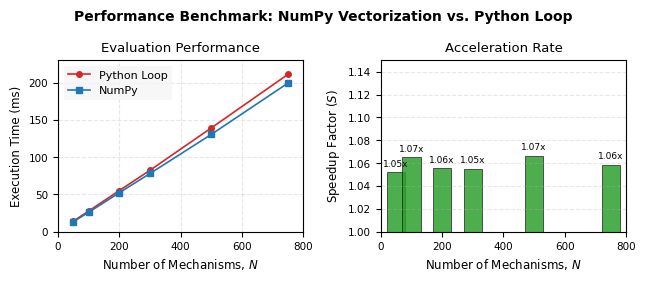

In [11]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# Dynamic naming system according to the guidelines
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_11_1_benchmark_numpy"
except Exception:
    notebook_name = "Figure_11_1_benchmark_numpy"

# Configure Springer-compliant publishing settings
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Helvetica', 'Arial']
plt.rcParams['font.size'] = 8
plt.rcParams['axes.labelsize'] = 8.5
plt.rcParams['axes.titlesize'] = 9.5
plt.rcParams['legend.fontsize'] = 8
plt.rcParams['xtick.labelsize'] = 7.5
plt.rcParams['ytick.labelsize'] = 7.5

# Data points
n_values = np.array([50, 100, 200, 300, 500, 750])
t_loop_v = np.array([14.2, 27.8, 55.3, 82.5, 139.4, 211.3])
t_np_v = np.array([13.5, 26.1, 52.4, 78.2, 130.7, 199.6])
speedup = t_loop_v / t_np_v

# Create physical figure layout (Springer double-column layout fits ~11-12 cm width beautifully)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.5, 2.8))

# Left plot: Evaluation Time
ax1.plot(n_values, t_loop_v, 'o-', color='#D62728', linewidth=1.2, markersize=4, label='Python Loop')
ax1.plot(n_values, t_np_v, 's-', color='#1F77B4', linewidth=1.2, markersize=4, label='NumPy')
ax1.set_xlabel('Number of Mechanisms, $N$')
ax1.set_ylabel('Execution Time (ms)')
ax1.set_title('Evaluation Performance')
ax1.legend(frameon=True, fancybox=False, edgecolor='none', facecolor='#F5F5F5')
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.set_xlim(0, 800)
ax1.set_ylim(0, 230) # Safe margins to prevent label/title overlapping

# Right plot: Speedup Factor
bars = ax2.bar(n_values, speedup, width=60, color='#2CA02C', alpha=0.85, edgecolor='black', linewidth=0.5)
ax2.set_xlabel('Number of Mechanisms, $N$')
ax2.set_ylabel('Speedup Factor ($S$)')
ax2.set_title('Acceleration Rate')
ax2.grid(axis='y', linestyle='--', alpha=0.3)
ax2.set_xlim(0, 800)
ax2.set_ylim(1.0, 1.15) # Safe margins

# Add values above bars dynamically to prevent overlap and ensure absolute clarity
for bar in bars:
    height = bar.get_height()
    ax2.annotate(f'{height:.2f}x',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontsize=6.5)

# Global Figure Adjustments
plt.suptitle('Performance Benchmark: NumPy Vectorization vs. Python Loop', fontweight='bold', fontsize=10)
plt.tight_layout()

# Double Export Option
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()